CS 6625 - Machine Learning-Based Phishing URL Detection

Student Name: Joel D. Sanchez# New Section

# Week 2: Dataset Exploration

Part 3: Install the UCI Dataset Package

In [108]:
!pip install -q ucimlrepo

Part 4: Import Python Libraries

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo


Part 5: Load the PhiUSIIL Dataset

In [110]:
phiusiil = fetch_ucirepo(id=967)

X = phiusiil.data.features.copy()
y = phiusiil.data.targets.squeeze().copy()

In [111]:
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (235795, 54)
Target shape: (235795,)


Part 7: Examine the First Rows

In [112]:
pd.set_option("display.max_columns", 12)
X.head()

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,...,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,...,34,20,28,119,0,124
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,...,50,9,8,39,0,217
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,...,10,2,7,42,2,5
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,...,3,27,15,22,1,31
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,...,244,15,34,72,1,85


Part 8: Examine Feature Names

In [113]:
print(X.columns.tolist())

['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


Part 9: Examine the Labels

In [114]:
print(y.value_counts())

label
1    134850
0    100945
Name: count, dtype: int64


Part 11: Examine Class Distribution

In [115]:

class_counts = y.value_counts().sort_index()
print(class_counts)

label
0    100945
1    134850
Name: count, dtype: int64


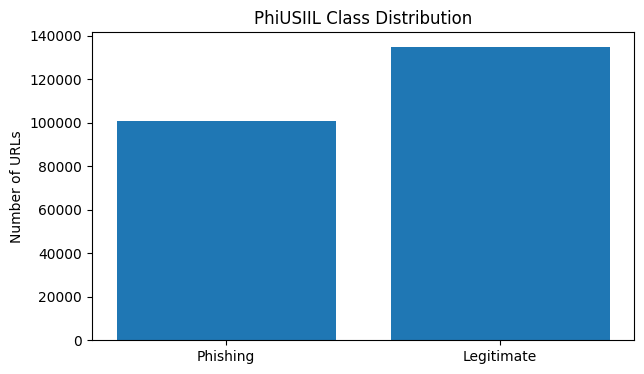

In [116]:
labels = ["Phishing", "Legitimate"]

counts = [
    class_counts.loc[0],
    class_counts.loc[1]
]

plt.figure(figsize=(7, 4))
plt.bar(labels, counts)

plt.ylabel("Number of URLs")
plt.title("PhiUSIIL Class Distribution")

plt.show()

Part 13: Examine Data Types

In [117]:
print(X.dtypes.value_counts())

int64      40
float64    10
object      4
Name: count, dtype: int64


In [118]:
numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

non_numeric_columns = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numeric columns:", len(numeric_columns))
print("Non-numeric columns:", len(non_numeric_columns))

print(non_numeric_columns)

Numeric columns: 50
Non-numeric columns: 4
['URL', 'Domain', 'TLD', 'Title']


Part 14: Check for Missing Values

In [119]:
missing_total = X.isna().sum().sum()

print(
    "Total missing feature values:",
    missing_total
)

Total missing feature values: 0


Part 15: Descriptive Statistics

In [120]:
X.select_dtypes(
    include=np.number
).describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6097.000000
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,110.000000
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,100.000000
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,0.522907
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,0.090824
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,13.000000
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,10.000000
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000


Part 16: Compare URL Length

In [121]:
analysis_df = X[
    ["URLLength", "DomainLength", "IsDomainIP"]
].copy()

analysis_df["Label"] = y.values

In [122]:
analysis_df.groupby(
    "Label"
)["URLLength"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Label,,,,,
0,100945,45.720293,34.0,13,6097
1,134850,26.228610,26.0,15,57


Part 17: Compare Domain Length

In [123]:
analysis_df.groupby(
    "Label"
)["DomainLength"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Label,,,,
0,24.465144,22.0,4,110
1,19.228610,19.0,8,50


Part 18: Examine IsDomainIP

In [124]:
pd.crosstab(
    analysis_df["Label"],
    analysis_df["IsDomainIP"],
    normalize="index"
)

IsDomainIP,0,1
Label,,
0,0.99368,0.00632
1,1.00000,0.00000


Advanced Study 1: Recode the Target

In [125]:
phishing_target = (y == 0).astype(int)

In [126]:
print(
    phishing_target.value_counts()
)

label
0    134850
1    100945
Name: count, dtype: int64


Advanced Study 2: Correlation

In [127]:
numeric_df = X.select_dtypes(
    include=np.number
).copy()

numeric_df["Phishing"] = phishing_target.values

In [128]:
correlations = (
    numeric_df.corr(numeric_only=True)["Phishing"]
    .drop("Phishing")
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

correlations.head(15)

,Phishing
URLSimilarityIndex,-0.860358
HasSocialNet,-0.784255
HasCopyrightInfo,-0.743358
HasDescription,-0.690232
IsHTTPS,-0.609132
DomainTitleMatchScore,-0.584905
HasSubmitButton,-0.578561
IsResponsive,-0.548608
URLTitleMatchScore,-0.539419
SpacialCharRatioInURL,0.533537


Optional Challenge: Feature Distributions

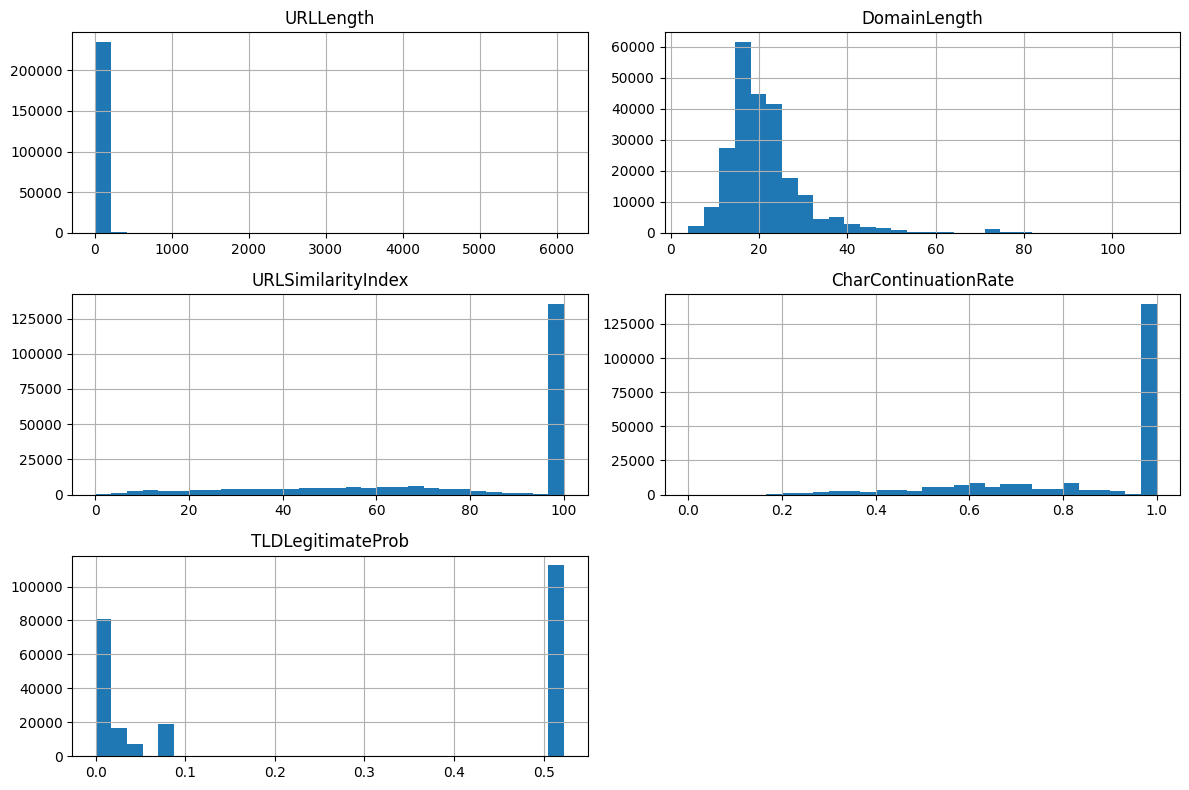

In [129]:
selected_features = [
    "URLLength",
    "DomainLength",
    "URLSimilarityIndex",
    "CharContinuationRate",
    "TLDLegitimateProb"
]

X[selected_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

# Week 3: Data Preparation and Train/Test Split

Part 3: Load the Dataset

In [130]:
!pip install -q ucimlrepo

In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

In [132]:
phiusiil = fetch_ucirepo(id=967)

X_raw = phiusiil.data.features.copy()
y_original = phiusiil.data.targets.squeeze().copy()

In [133]:
print(X_raw.shape)
print(y_original.shape)

(235795, 54)
(235795,)


Part 4: Recode the Target

In [134]:
y = (y_original == 0).astype(int)
y.name = "Phishing"

In [135]:
print(y.value_counts())

Phishing
0    134850
1    100945
Name: count, dtype: int64


Part 5: Select Numeric Features

In [136]:
X = X_raw.select_dtypes(
    include=np.number
).copy()

In [137]:
print(X.shape)
print(X.columns.tolist())

(235795, 50)
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


Part 6: Verify the Data

In [138]:
print(
    "Number of X rows:",
    len(X)
)

print(
    "Number of y values:",
    len(y)
)

Number of X rows: 235795
Number of y values: 235795


In [139]:
print(
    "Missing values:",
    X.isna().sum().sum()
)

Missing values: 0


Part 7: Explore Selected Features

In [140]:
selected_features = [
    "URLLength",
    "DomainLength",
    "URLSimilarityIndex",
    "CharContinuationRate",
    "TLDLegitimateProb"
]

In [141]:
X[selected_features].describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6097.000000
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,110.000000
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,100.000000
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,0.522907


Part 8: Compare Features by Class

In [142]:
analysis_df = X[
    selected_features
].copy()

analysis_df["Phishing"] = y.values

In [143]:
analysis_df.groupby(
    "Phishing"
)[selected_features].mean().T

Phishing,0,1
URLLength,26.228610,45.720293
DomainLength,19.228610,24.465144
URLSimilarityIndex,100.000000,49.616973
CharContinuationRate,0.933176,0.728395
TLDLegitimateProb,0.281625,0.232099


Part 9: Visualize URL Length

In [144]:
legitimate_url_length = analysis_df.loc[
    analysis_df["Phishing"] == 0,
    "URLLength"
]

phishing_url_length = analysis_df.loc[
    analysis_df["Phishing"] == 1,
    "URLLength"
]

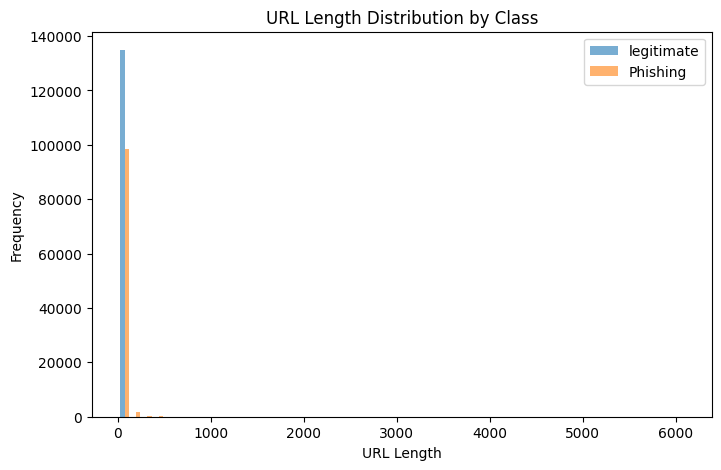

In [145]:
plt.figure(figsize=(8, 5))

plt.hist(
    [
        legitimate_url_length,
        phishing_url_length
    ],
    bins=50,
    label=[
        "legitimate",
        "Phishing"
    ],
    alpha=0.6
)

plt.xlabel("URL Length")
plt.ylabel("Frequency")

plt.title(
    "URL Length Distribution by Class"
)

plt.legend()

plt.show()

Part 11: Create the Official Course Split

In [146]:
from sklearn.model_selection import train_test_split

In [147]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Part 12: What Does test_size=0.20 Mean?

In [148]:
print(
    "X_train:",
    X_train.shape
)

print(
    "X_test:",
    X_test.shape
)

X_train: (188636, 50)
X_test: (47159, 50)


Part 15: Verify Class Distribution

In [149]:
print(
    "Full dataset:"
)

print(
    y.value_counts(
        normalize=True
    )
)

Full dataset:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


In [150]:
print(
    "Training:"
)

print(
    y_train.value_counts(
        normalize=True
    )
)

Training:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


In [151]:
print(
    "Testing:"
)

print(
    y_test.value_counts(
        normalize=True
    )
)

Testing:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


Part 16: Verify Reproducibility

In [152]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [153]:
print(
    X_train.index.equals(
        X_train2.index
    )
)

print(
    X_test.index.equals(
        X_test2.index
    )
)

True
True


Advanced Study 1: What Happens Without Stratification?

In [154]:
_, X_test_temp, _, y_test_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [155]:
print(
    "Stratified:"
)

print(
    y_test.value_counts(
        normalize=True
    )
)

print(
    "Not Stratified:"
)

print(
    y_test_temp.value_counts(
        normalize=True
    )
)

Stratified:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64
Not Stratified:
Phishing
0    0.573273
1    0.426727
Name: proportion, dtype: float64


Advanced Study 2: Different Random Seeds

In [156]:
for seed in [
    1,
    21,
    42,
    100
]:

    _, X_temp, _, y_temp = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )

    print(
        seed,
        y_temp.mean()
    )

1 0.42810492164804176
21 0.42810492164804176
42 0.42810492164804176
100 0.42810492164804176


# Week 4: Logistic Regression and Classification Metrics



Part 7: Build the Pipeline

In [157]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [158]:
lr_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000
        )
    )
])

Part 8: Train the Model

In [159]:
lr_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=2000))])

Part 9: Generate Predictions

In [160]:
lr_pred = lr_model.predict(
    X_test
)

In [161]:
print(
    lr_pred[:20]
)

[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


In [162]:
print(
    y_test.iloc[:20].to_numpy()
)

[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


Part 10: Prediction vs Probability

In [163]:
lr_prob = lr_model.predict_proba(
    X_test
)[:, 1]

In [164]:
print(
    lr_prob[:10]
)

[7.76971563e-07 9.99999753e-01 1.85108133e-04 1.00000000e+00
 8.82577634e-05 3.54717718e-07 9.99711349e-01 9.99999574e-01
 6.63741195e-14 6.65616758e-09]


Part 11: Preview Predictions and Probabilities

In [165]:
probability_preview = pd.DataFrame({
    "Actual":
      y_test.iloc[:10].to_numpy(),

    "Predicted":
      lr_pred[:10],

    "Phishing Probability":
      lr_prob[:10]
})

probability_preview

,Actual,Predicted,Phishing Probability
0,0,0,7.769716e-07
1,1,1,9.999998e-01
2,0,0,1.851081e-04
3,1,1,1.000000e+00
4,0,0,8.825776e-05
5,0,0,3.547177e-07
6,1,1,9.997113e-01
7,1,1,9.999996e-01
8,0,0,6.637412e-14
9,0,0,6.656168e-09


Part 12: Model Evaluation

In [166]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [167]:
lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

lr_precision = precision_score(
    y_test,
    lr_pred
)

lr_recall = recall_score(
    y_test,
    lr_pred
)

lr_f1 = f1_score(
    y_test,
    lr_pred
)

lr_auc = roc_auc_score(
    y_test,
    lr_prob
)

In [168]:
print(
    f"Accuracy : {lr_accuracy:.4f}"
)

print(
    f"Precision : {lr_precision:.4f}"
)

print(
    f"Recall : {lr_recall:.4f}"
)

print(
    f"F1-score : {lr_f1:.4f}"
)

print(
    f"ROC-AUC : {lr_auc:.4f}"
)

Accuracy : 0.9999
Precision : 1.0000
Recall : 0.9998
F1-score : 0.9999
ROC-AUC : 1.0000


Part 18: Confusion Matrix

In [169]:
from sklearn.metrics import(
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [170]:
cm = confusion_matrix(
    y_test,
    lr_pred
)

print(cm)

[[26970     0]
 [    5 20184]]


Part 20:

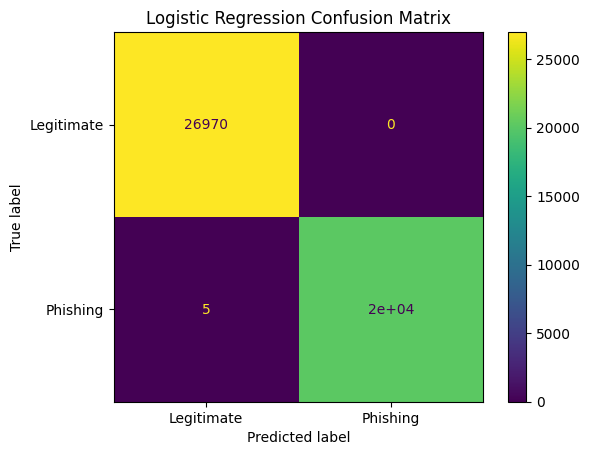

In [171]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
).plot()

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.show()

Part 22: Classification Report

In [172]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        lr_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ]
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     26970
    Phishing       1.00      1.00      1.00     20189

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159



Part 24: Plot the ROC Curve

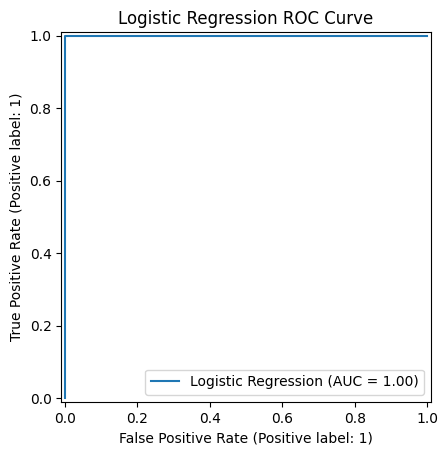

In [173]:
from sklearn.metrics import(
    RocCurveDisplay
)

RocCurveDisplay.from_predictions(
    y_test,
    lr_prob,
    name = "Logistic Regression"
)

plt.title(
    "Logistic Regression ROC Curve"
)

plt.show()

Part 25: Start Your Final Model Comparison Table

In [174]:
model_results = pd.DataFrame([
    {
        "Model":
          "Logistic Regression",

        "Accuracy":
          lr_accuracy,

        "Precision":
          lr_precision,

        "Recall":
          lr_recall,

        "F1-score":
          lr_f1,

        "ROC-AUC":
          lr_auc
    }
])

model_results

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.999894,1.0,0.999752,0.999876,1.0


Advanced Threshold Experiment

In [175]:
def evaluate_threshold(
    threshold
):

    predictions = (
        lr_prob >= threshold
    ).astype(int)

    return {
        "Threshold":
            threshold,

        "Accuracy":
            accuracy_score(
                y_test,
                predictions
            ),

        "Precision":
            precision_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "F1-score":
            f1_score(
                y_test,
                predictions,
                zero_division=0
            )
    }

In [176]:
threshold_results = pd.DataFrame([
    evaluate_threshold(0.30),
    evaluate_threshold(0.50),
    evaluate_threshold(0.70)
])

threshold_results

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.999979,1.0,0.999950,0.999975
1,0.5,0.999894,1.0,0.999752,0.999876
2,0.7,0.999788,1.0,0.999505,0.999752


Advanced Study 2: Precision-Recall Curve

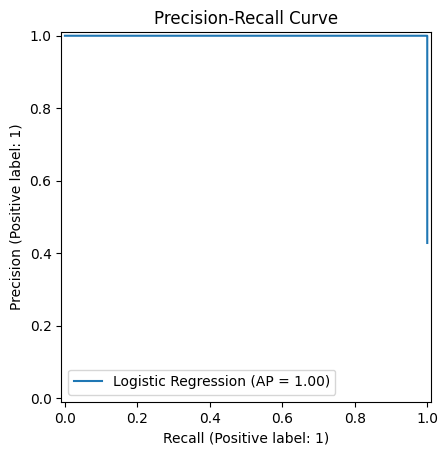

In [177]:
from sklearn.metrics import (
    PrecisionRecallDisplay
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    lr_prob,
    name="Logistic Regression"
)

plt.title(
    "Precision-Recall Curve"
)

plt.show()

Advanced Study 3: Logistic Regression Coefficients

In [178]:
classifier = lr_model.named_steps[
    "classifier"
]

In [179]:
coefficient_df = pd.DataFrame({
    "Feature":
        X_train.columns,

    "Coefficient":
        classifier.coef_[0]
})

In [180]:
coefficient_df[
    "Absolute_Coefficient"
] = coefficient_df[
    "Coefficient"
].abs()

In [181]:
coefficient_df = (
    coefficient_df
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
)

coefficient_df.head(15)

,Feature,Coefficient,Absolute_Coefficient
3,URLSimilarityIndex,-6.956245,6.956245
21,IsHTTPS,-3.879599,3.879599
20,SpacialCharRatioInURL,1.887845,1.887845
13,LetterRatioInURL,1.774712,1.774712
46,NoOfJS,-1.770485,1.770485
36,HasSocialNet,-1.478811,1.478811
47,NoOfSelfRef,-1.383850,1.383850
44,NoOfImage,-1.261538,1.261538
8,NoOfSubDomain,-1.259081,1.259081
15,DegitRatioInURL,1.233362,1.233362


Advanced Study 5: Class Weighting

In [182]:
lr_balanced = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
])

In [183]:
lr_balanced.fit(
    X_train,
    y_train
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

In [184]:
balanced_pred = (
    lr_balanced.predict(
        X_test
    )
)

In [185]:
print(
    "Default recall:",
    recall_score(
        y_test,
        lr_pred
    )
)

print(
    "Balanced recall:",
    recall_score(
        y_test,
        balanced_pred
    )
)

Default recall: 0.9997523403833771
Balanced recall: 0.9998018723067017


# Week 5: Decision Tree Phishing Detection

Part 8: Import DecisionTreeClassifier

In [186]:
from sklearn.tree import DecisionTreeClassifier

Part 9: Build the Decision Tree

In [187]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

Part 10: Train the Decision Tree

In [188]:
dt_model.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(max_depth=5, random_state=42)

Part 11: Generate Predictions

In [189]:
dt_pred = dt_model.predict(
    X_test
)

In [190]:
print(
    dt_pred[:20]
)

[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


Part 12: Check the Actual Tree Depth

In [191]:
print(
    dt_model.get_depth()
)

4


In [192]:
print(
    dt_model.get_n_leaves()
)

5


Part 13: Evaluate the Decision Tree

In [193]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [194]:
dt_accuracy = accuracy_score(
    y_test,
    dt_pred
)

dt_precision = precision_score(
    y_test,
    dt_pred
)

dt_recall = recall_score(
    y_test,
    dt_pred
)

dt_f1 = f1_score(
    y_test,
    dt_pred
)

In [195]:
print(
    f"Accuracy : {dt_accuracy:.4f}"
)

print(
    f"Precision : {dt_precision:.4f}"
)

print(
    f"Recall : {dt_recall:.4f}"
)

print(
    f"F1-score : {dt_f1:.4f}"
)

Accuracy : 1.0000
Precision : 1.0000
Recall : 1.0000
F1-score : 1.0000


Part 15: Create the Confusion Matrix

In [196]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [197]:
cm = confusion_matrix(
    y_test,
    dt_pred
)

print(cm)

[[26970     0]
 [    0 20189]]


Part 16: Display the Confusion Matrix

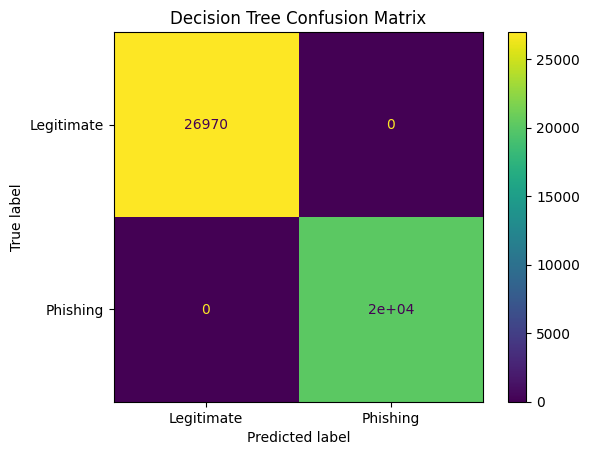

In [198]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
).plot()

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.show()

Part 18: Training Performance vs. Testing Performance

In [199]:
train_accuracy = dt_model.score(
    X_train,
    y_train
)

test_accuracy = dt_model.score(
    X_test,
    y_test
)

print(
    "Training accuracy:",
    train_accuracy
)

print(
    "Testing accuracy:",
    test_accuracy
)

Training accuracy: 1.0
Testing accuracy: 1.0


Advanced Study 1: Depth Experiment

In [200]:
for depth in [
    1,
    3,
    5,
    10,
    20,
    None
]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    print(
        depth,
        "Train:",
        model.score(
            X_train,
            y_train
        ),
        "Test:",
        model.score(
            X_test,
            y_test
        )
    )


1 Train: 0.9966390296655994 Test: 0.9967768612566
3 Train: 0.999989397569923 Test: 1.0
5 Train: 1.0 Test: 1.0
10 Train: 1.0 Test: 1.0
20 Train: 1.0 Test: 1.0
None Train: 1.0 Test: 1.0


Advanced Study 5: Visualizing the Tree

In [201]:
from sklearn.tree import plot_tree

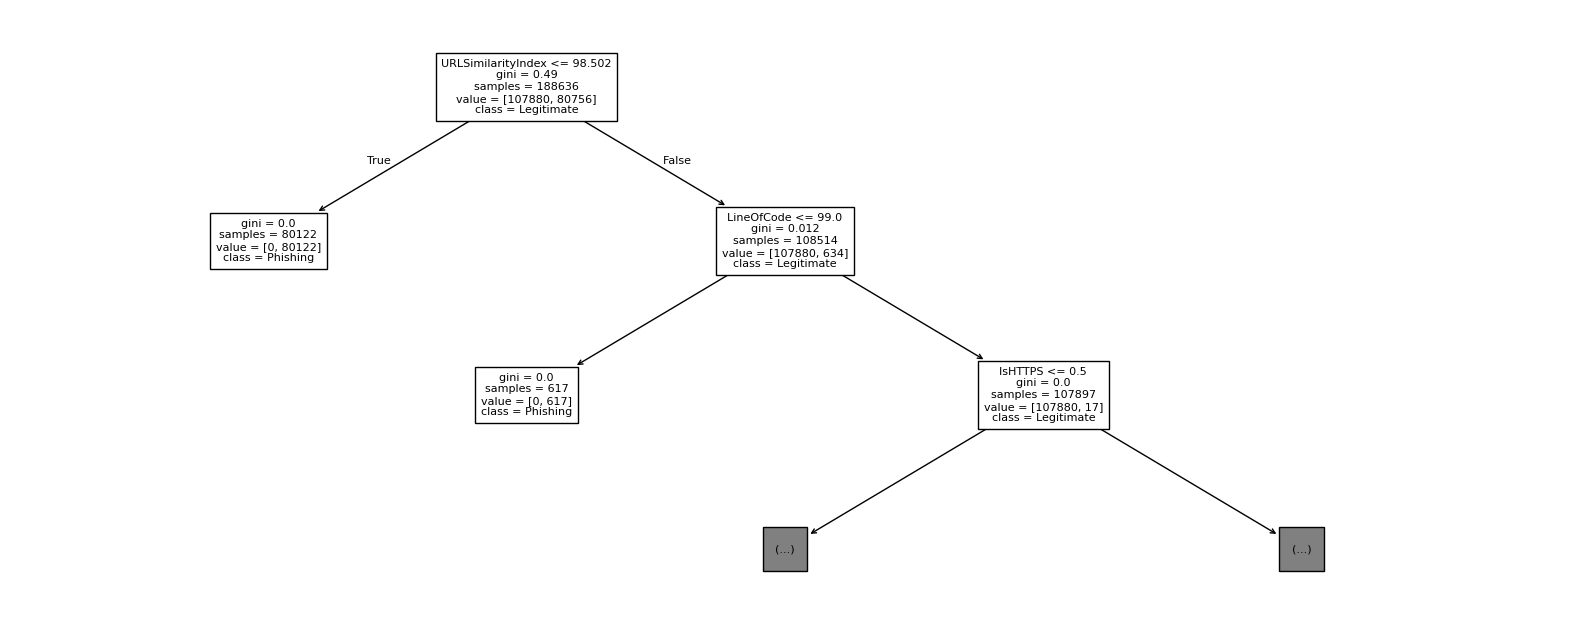

In [202]:
plt.figure(
    figsize=(20, 8)
)

plot_tree(
    dt_model,
    feature_names=
      X_train.columns,

    class_names=[
        "Legitimate",
        "Phishing"
    ],

    max_depth=2,

    filled=False,

    fontsize=8
)

plt.show()

Advanced Study 6: View Decision Rules as Text

In [203]:
from sklearn.tree import export_text

In [204]:
rules = export_text(
    dt_model,
    feature_names=
      list(
          X_train.columns
      ),
    max_depth=3
)

print(rules)

|--- URLSimilarityIndex <= 98.50
|   |--- class: 1
|--- URLSimilarityIndex >  98.50
|   |--- LineOfCode <= 99.00
|   |   |--- class: 1
|   |--- LineOfCode >  99.00
|   |   |--- IsHTTPS <= 0.50
|   |   |   |--- class: 1
|   |   |--- IsHTTPS >  0.50
|   |   |   |--- NoOfSubDomain <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- NoOfSubDomain >  0.50
|   |   |   |   |--- class: 0



# Homework 5: Decision Tree Phishing Detection

Part 1 - Prepared Data (10 points)

In [205]:
print("X_train: ", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train: ", y_train.shape)
print("y_test: ", y_test.shape)

X_train:  (188636, 50)
X_test:  (47159, 50)
y_train:  (188636,)
y_test:  (47159,)


Part 2 - Train a Decision Tree (25 points)

In [206]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("Decision Tree training and prediction completed successfully.")

Decision Tree training and prediction completed successfully.


Part 3 - Evaluate the Model (25 pints)

In [207]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print(f"Accuracy: {dt_accuracy:.4f} ({dt_accuracy:.2%})")
print(f"Precision: {dt_precision:.4f} ({dt_precision:.2%})")
print(f"Recall: {dt_recall:.4f} ({dt_recall:.2%})")
print(f"F1-score: {dt_f1:.4f} ({dt_f1:.2%})")

Accuracy: 1.0000 (100.00%)
Precision: 1.0000 (100.00%)
Recall: 1.0000 (100.00%)
F1-score: 1.0000 (100.00%)


Part 4 - Confusion Matrix (15 points)

Confusion matrix (rows = actual, columns = predicted):
[[26970     0]
 [    0 20189]]


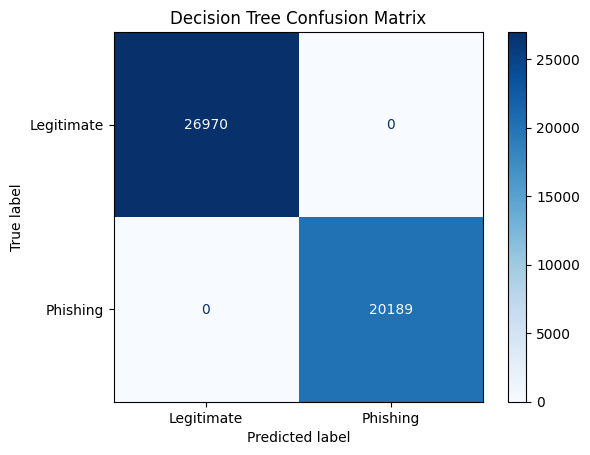

In [208]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, dt_test_pred, labels=[0, 1])
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
).plot(cmap="Blues", values_format="d")
plt.title("Decision Tree Confusion Matrix")

plt.show()

1. What does a true positive mean in this phishing-detection project?
    - A true positive occurs when a URL is actually phishing and the Decision Tree correctly predicts it as phishing. This means the model successfully identifies a phishing threat.

2. What does a false negative mean in this phishing-detection project?
    - A false negative occurs when a URL is actually phishing, but the Decision Tree incorrectly predicts it as legitimate. This is dangerous because a malicious URL could go undetected.

Part 5 - Short Analysis (25 points)
   
Question 1: what is a Decision Tree?
- A Decision Tree is a supervised machine-learning algorithm that classifies data by following a series of feature-based decisions. Each internal node tests a feature, and each leaf gives a predicted class, such as legitimate or phishing.

Question 2: What does max_depth=5 control?
- It limits the maximum number of splits along a path from the root to a leaf to five. This controls model complexity and can reduce overfitting, although the tree may stop growing earlier.

Question 3: Why might a very deep Decision Tree overfit the training data?
- A very deep tree can learn small details, noise, or unusual patterns specific to its training examples instead of general phishing characteristics. It may perform extremely well on training data but less accurately on new, unseen URLs.

Question 4: Which metric do you think is especially important for phishing detection? (Accuracy, Precision, Recall, F1-score)
- Recall is especially important because it measures the porprtion of actual phishing URLs correctly detected. A low recall means more false negatives, allowing gdangerous phishing links to be classified as legitimate. Precision is also valuable for limiting false alarms, but detecting real threats is a priority.




Additional Model Evaluation Observation:
- The Decision Tree acheived 100% accuracy, precission, recall, and F1-score on the test dataset. Additional validation (not included in the homework submission) showed that the model's performance was not caused by exact duplicate feature patterns between the training and testing sets. Feature importance analysis revealed that URLSimilarityIndex accounted for approximately 98.64% of the Decision Tree's feature importance. Although the model performed perfectly on this dataset, the strong relationship between this feature and the target labels suggests that further evaluation would be necessary to determine whether the model generalizes equally well to new phishing URLs.